In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path("..") / "data" / "raw" / "vaastav"

seasons = {}
for path in sorted(DATA.glob("*.csv")):
    seasons[path.stem] = pd.read_csv(path, low_memory=False)

for name, df in seasons.items():
    print(name, df.shape)

2016-17 (23679, 56)
2017-18 (22467, 56)
2018-19 (21790, 56)
2019-20 (22560, 33)
2020-21 (24365, 36)
2021-22 (25447, 36)
2022-23 (26505, 41)
2023-24 (29725, 41)
2024-25 (27605, 49)
2025-26 (29757, 46)


In [3]:
common = set.intersection(*(set(df.columns) for df in seasons.values()))
print(len(common), "zajednickih kolona:")
print(sorted(common))

for name, df in seasons.items():
    extra = sorted(set(df.columns) - common)
    print(f"\n{name} ima dodatno ({len(extra)}): {extra}")

33 zajednickih kolona:
['GW', 'assists', 'bonus', 'bps', 'clean_sheets', 'creativity', 'element', 'fixture', 'goals_conceded', 'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes', 'name', 'opponent_team', 'own_goals', 'penalties_missed', 'penalties_saved', 'red_cards', 'round', 'saves', 'selected', 'team_a_score', 'team_h_score', 'threat', 'total_points', 'transfers_balance', 'transfers_in', 'transfers_out', 'value', 'was_home', 'yellow_cards']

2016-17 ima dodatno (23): ['attempted_passes', 'big_chances_created', 'big_chances_missed', 'clearances_blocks_interceptions', 'completed_passes', 'dribbles', 'ea_index', 'errors_leading_to_goal', 'errors_leading_to_goal_attempt', 'fouls', 'id', 'key_passes', 'kickoff_time_formatted', 'loaned_in', 'loaned_out', 'offside', 'open_play_crosses', 'penalties_conceded', 'recoveries', 'tackled', 'tackles', 'target_missed', 'winning_goals']

2017-18 ima dodatno (23): ['attempted_passes', 'big_chances_created', 'big_chances_missed', 'cle

In [4]:
POSITIONS = {1: "GK", 2: "DEF", 3: "MID", 4: "FWD"}
BASE_COLS = sorted(common)
EXTRA_COLS = ["expected_goals", "expected_assists",
              "expected_goal_involvements", "expected_goals_conceded",
              "starts", "xP"]

frames = []
for name, df in seasons.items():
    cols = BASE_COLS + [c for c in EXTRA_COLS if c in df.columns]
    df = df[cols].copy()

    players = pd.read_csv(DATA / "players" / f"{name}.csv", low_memory=False)
    players = players[["id", "element_type", "team"]].rename(columns={"id": "element"})
    df = df.merge(players, on="element", how="left")

    df["position"] = df["element_type"].map(POSITIONS)  # menadzeri (tip 5) dobijaju NaN
    df["season"] = name
    frames.append(df)

all_gw = pd.concat(frames, ignore_index=True)
print("Pre filtriranja:", all_gw.shape)

all_gw = all_gw[all_gw["position"].notna()]
print("Posle izbacivanja menadzera:", all_gw.shape)

all_gw.groupby("season")["position"].value_counts().unstack()

Pre filtriranja: (253900, 43)
Posle izbacivanja menadzera: (253578, 43)


position,DEF,FWD,GK,MID
season,,,,
2016-17,7620,3640,2343,10076
2017-18,7438,3151,2401,9477
2018-19,7649,3143,2290,8708
2019-20,7658,3063,2555,9284
2020-21,8626,3113,2768,9858
2021-22,8620,3398,2910,10519
2022-23,9183,3113,2791,11418
2023-24,9611,3854,3413,12847
2024-25,9146,3018,2869,12250


In [5]:
all_gw["played"] = all_gw["minutes"] > 0
print("Udeo redova bez ijednog minuta:", round(1 - all_gw["played"].mean(), 3))

all_gw[all_gw["played"]].groupby("position")["total_points"].describe().round(2)

Udeo redova bez ijednog minuta: 0.571


,count,mean,std,min,25%,50%,75%,max
position,,,,,,,,
DEF,36357.0,2.80,3.02,-7.0,1.0,2.0,5.0,24.0
FWD,14811.0,3.08,3.26,-2.0,1.0,2.0,4.0,24.0
GK,7677.0,3.52,2.81,-3.0,2.0,2.0,6.0,17.0
MID,49842.0,2.84,2.88,-2.0,1.0,2.0,3.0,29.0


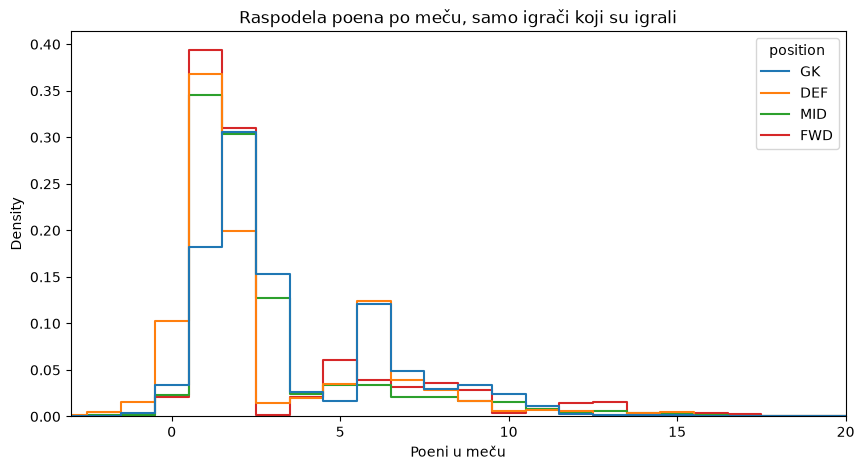

In [6]:
played = all_gw[all_gw["played"]]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=played, x="total_points", hue="position",
             hue_order=["GK", "DEF", "MID", "FWD"],
             discrete=True, stat="density", common_norm=False,
             element="step", fill=False, ax=ax)
ax.set_xlim(-3, 20)
ax.set_title("Raspodela poena po meču, samo igrači koji su igrali")
ax.set_xlabel("Poeni u meču")
plt.show()

In [7]:
all_gw["minutes_group"] = pd.cut(all_gw["minutes"], bins=[-1, 0, 59, 90],
                                 labels=["0 min", "1-59 min", "60-90 min"])

all_gw.groupby(["minutes_group", "position"], observed=True)["total_points"] \
      .mean().unstack().round(2)

position,DEF,FWD,GK,MID
minutes_group,,,,
0 min,-0.00,-0.00,-0.00,-0.00
1-59 min,0.88,1.51,0.83,1.29
60-90 min,3.19,4.25,3.56,3.63


In [8]:
cols = ["season", "round", "name", "position", "minutes", "goals_scored",
        "assists", "bonus", "total_points"]

print("Najveci broj poena:")
display(all_gw.nlargest(5, "total_points")[cols])

print("0 minuta, a poeni razliciti od 0:")
display(all_gw[(all_gw["minutes"] == 0) & (all_gw["total_points"] != 0)][cols])

Najveci broj poena:


,season,round,name,position,minutes,goals_scored,assists,bonus,total_points
37885,2017-18,31,Mohamed_Salah,MID,90,4,1,3,29
88305,2019-20,44,Michail_Antonio_389,MID,77,4,0,3,26
191464,2023-24,33,Cole Palmer,MID,79,4,0,3,26
199762,2024-25,6,Cole Palmer,MID,90,4,0,3,25
18846,2016-17,37,Harry_Kane,FWD,90,4,1,3,24


0 minuta, a poeni razliciti od 0:


,season,round,name,position,minutes,goals_scored,assists,bonus,total_points
28671,2017-18,17,Sam_Field,MID,0,0,0,0,-1
42368,2017-18,38,Ederson_Santana de Moraes,GK,0,0,0,0,-1
83315,2019-20,28,Ezequiel_Schelotto_546,DEF,0,0,0,0,-1
113650,2020-21,37,Daniel Amartey,DEF,0,0,0,0,-1
133550,2021-22,30,Nohan Kenneh,MID,0,0,0,0,-1
149161,2022-23,16,Jamaal Lascelles,DEF,0,0,0,0,-1
151230,2022-23,19,Jamaal Lascelles,DEF,0,0,0,0,-1
158278,2022-23,28,Matheus Luiz Nunes,MID,0,0,0,0,-3
168460,2023-24,3,Marek Rodák,GK,0,0,0,0,-1
179117,2023-24,18,Marcus Bettinelli,GK,0,0,0,0,-1


In [9]:
played.groupby(["position", "was_home"])["total_points"].mean().unstack().round(2)

was_home,False,True
position,,
DEF,2.55,3.06
FWD,2.92,3.25
GK,3.39,3.65
MID,2.71,2.97


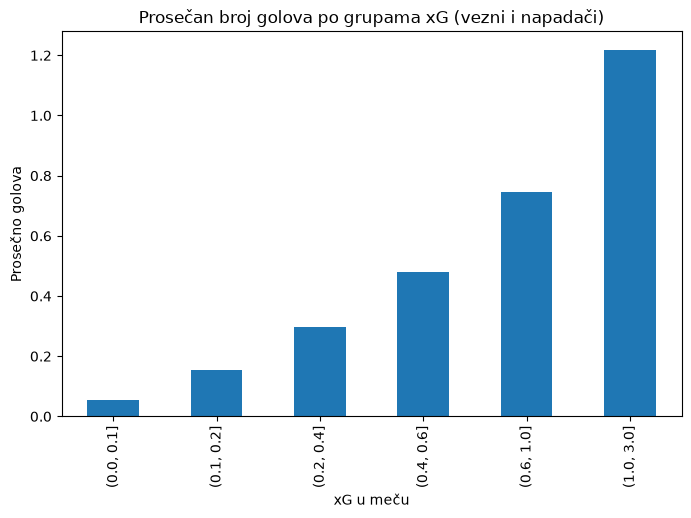

Korelacija xG i golova: 0.576


In [10]:
xg = played.dropna(subset=["expected_goals"])
xg = xg[xg["position"].isin(["MID", "FWD"])]

fig, ax = plt.subplots(figsize=(8, 5))
xg.groupby(pd.cut(xg["expected_goals"], bins=[0, 0.1, 0.2, 0.4, 0.6, 1, 3]),
           observed=True)["goals_scored"].mean().plot(kind="bar", ax=ax)
ax.set_title("Prosečan broj golova po grupama xG (vezni i napadači)")
ax.set_xlabel("xG u meču")
ax.set_ylabel("Prosečno golova")
plt.show()

print("Korelacija xG i golova:", round(xg["expected_goals"].corr(xg["goals_scored"]), 3))

In [11]:
import numpy as np

p = played.copy()
p["team_conceded"] = np.where(p["was_home"], p["team_a_score"], p["team_h_score"])

# prosek primljenih golova po timu u sezoni
team_def = (
    p.drop_duplicates(["season", "fixture", "team"])
     .groupby(["season", "team"])["team_conceded"].mean()
     .rename("opp_conceded_avg").reset_index()
     .rename(columns={"team": "opponent_team"})
)
p = p.merge(team_def, on=["season", "opponent_team"], how="left")

labels = ["1 najjaca odbrana", "2", "3", "4", "5 najslabija odbrana"]
p["opp_group"] = pd.qcut(p["opp_conceded_avg"], 5, labels=labels)

p.groupby(["opp_group", "position"], observed=True)["total_points"] \
 .mean().unstack().round(2)

position,DEF,FWD,GK,MID
opp_group,,,,
1 najjaca odbrana,2.00,2.45,3.04,2.36
2,2.65,2.91,3.52,2.69
3,3.05,3.13,3.65,2.92
4,2.97,3.31,3.56,2.99
5 najslabija odbrana,3.39,3.66,3.87,3.26


Zaključci EDA faze (za kraj notebook-a i README)
57% redova su igrači bez minuta, pa je predviđanje minutaže najvažniji deo modela.
Poeni su diskretni i nakrivljeni, pa je glavna metrika MAE.
Domaćin donosi 0,3 do 0,5 poena više, najviše odbrani.
Rolling xG je dobar kandidat za feature (kalibrisan, korelacija 0,58 po meču).
Jačina protivnika menja očekivane poene za 30% do 70%.
Mečeve redamo po kickoff_time, ne po round (sezona 2019-20 ima kola do 47).